# Compute Scaling and Priors for Satellite $\rm \theta_E$

Given a measured velocity dispersion, $\rm \sigma_v$, and angular diameter distances, the Einstein radius for a Singular Isothermal Sphere (SIS) is:
$$
\rm \theta_E = 4\pi (\frac{\rm \sigma_v}{\rm c})^2 \frac{\rm D_{LS}}{\rm D_S}
$$

In [1]:
from astropy.cosmology import FlatLambdaCDM

def theta_E_from_vd(vd, dLS_over_dS):
    ans = 2.884e-5 * vd**2 * dLS_over_dS
    return ans

z_lens = 0.6575
z_source = 1.662

cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

dLS = cosmo.angular_diameter_distance(z_lens, z_source).value
dS = cosmo.angular_diameter_distance(z_source).value
dLS_over_dS = dLS / dS

d_vd = 204.6
d_vd_sigma = 6.1
theta_E_d = theta_E_from_vd(d_vd, dLS_over_dS)
theta_E_d_sigma = theta_E_d - theta_E_from_vd(d_vd-d_vd_sigma, dLS_over_dS)
print(f"Deflector theta_E = {theta_E_d:.3f} +/- {theta_E_d_sigma:.3f} arcsec")

g2_vd = 223
g2_vd_sigma = 12

g3_vd = 79
g3_vd_sigma = 18

g7_vd = 166
g7_vd_sigma = 6

theta_E_g2 = theta_E_from_vd(g2_vd, dLS_over_dS)
theta_E_g2_sigma = theta_E_g2 - theta_E_from_vd(g2_vd-g2_vd_sigma, dLS_over_dS)
print(f"G2 theta_E = {theta_E_g2:.3f} +/- {theta_E_g2_sigma:.3f} arcsec")

theta_E_g3 = theta_E_from_vd(g3_vd, dLS_over_dS)
theta_E_g3_sigma = theta_E_g3 - theta_E_from_vd(g3_vd-g3_vd_sigma, dLS_over_dS)
print(f"G3 theta_E = {theta_E_g3:.3f} +/- {theta_E_g3_sigma:.3f} arcsec")

theta_E_g7 = theta_E_from_vd(g7_vd, dLS_over_dS)
theta_E_g2_sigma = theta_E_g7 - theta_E_from_vd(g7_vd-g7_vd_sigma, dLS_over_dS)
print(f"G7 theta_E = {theta_E_g7:.3f} +/- {theta_E_g2_sigma:.3f} arcsec")

print("###########################")
print(f"Scaled to main lens theta_E ({theta_E_d:.3f} arcsec):")
print(f"G2: {theta_E_g2 / theta_E_d:.3f}")
print(f"G3: {theta_E_g3 / theta_E_d:.3f}")
print(f"G7: {theta_E_g7 / theta_E_d:.3f}")

Deflector theta_E = 0.589 +/- 0.035 arcsec
G2 theta_E = 0.700 +/- 0.073 arcsec
G3 theta_E = 0.088 +/- 0.035 arcsec
G7 theta_E = 0.388 +/- 0.028 arcsec
###########################
Scaled to main lens theta_E (0.589 arcsec):
G2: 1.188
G3: 0.149
G7: 0.658


# Create PSFs

In [1]:
from dolphin.preprocessing.psf import PSF

io_directory="starred_models"
lens_name="WFI2033"
data_band="F115W"
full_image_file=f"full_data/full_image_{lens_name}_{data_band}.fits"

psf = PSF(io_directory=io_directory,
          lens_name=lens_name,
          data_band=data_band,
          instrument="JWST",
          full_image_file=full_image_file
         )

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:123: RuntimeWarning: divide by zero encountered in divide
  + 1.0 / wht


Found 6 candidate objects!


/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:628: RuntimeWarning: invalid value encountered in log10
  im_star = ax[i].imshow(np.log10(star_exposures[i].data), cmap="viridis")


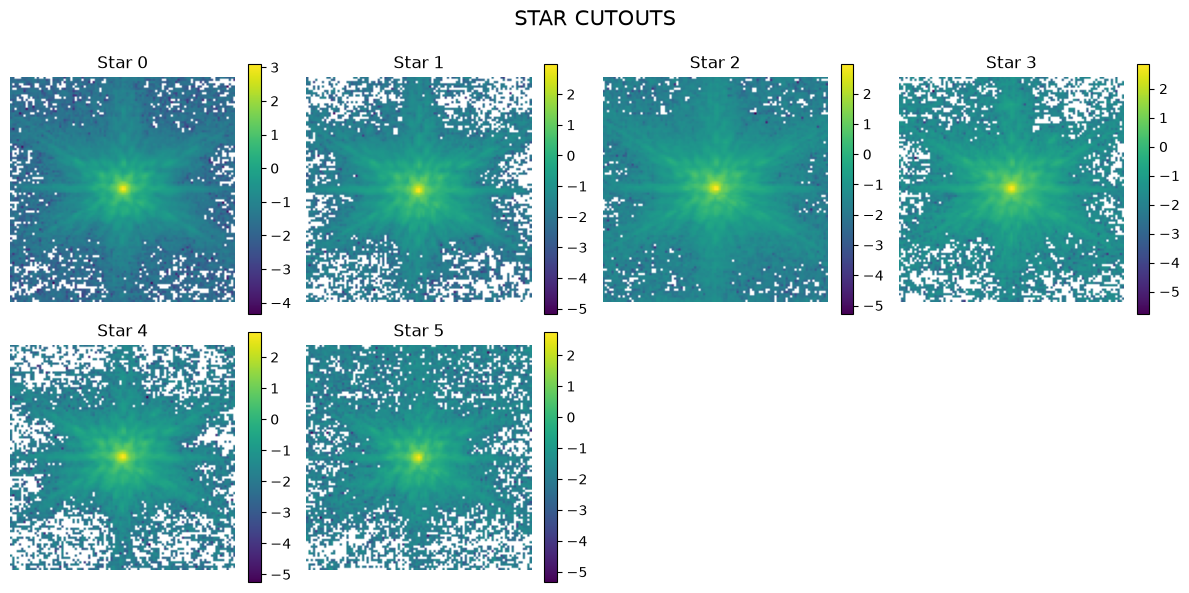

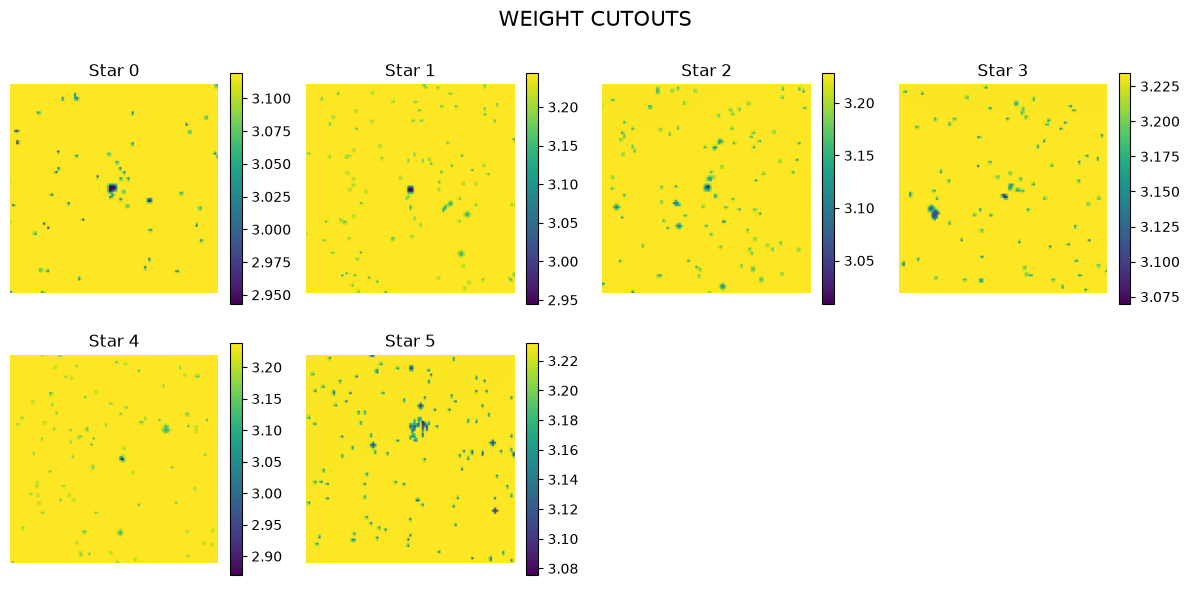

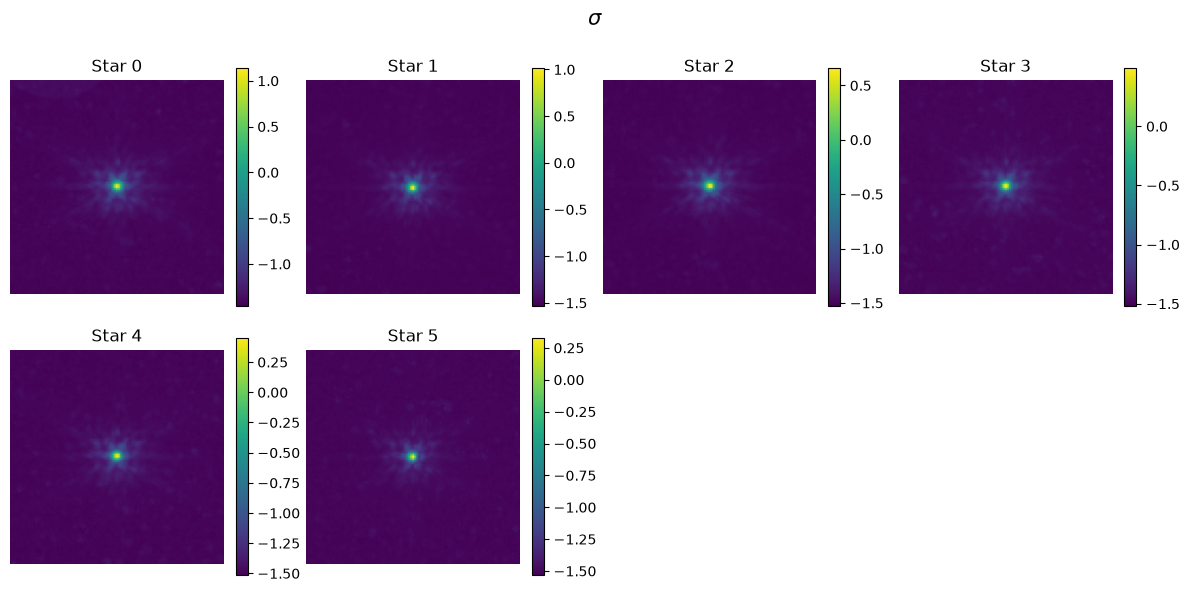

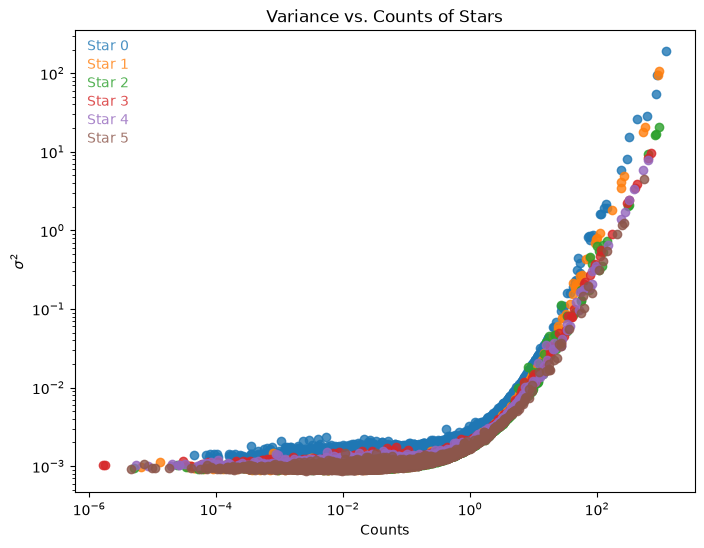

Set DATE-AVG to '2022-09-19T05:29:32.024' from MJD-AVG.
Set DATE-END to '2022-09-19T05:46:53.553' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to     0.765830 from OBSGEO-[XYZ].
Set OBSGEO-H to 1311263769.644 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:731: RuntimeWarning: invalid value encountered in log10
  plt_data = np.log10(data_full + 0.1)


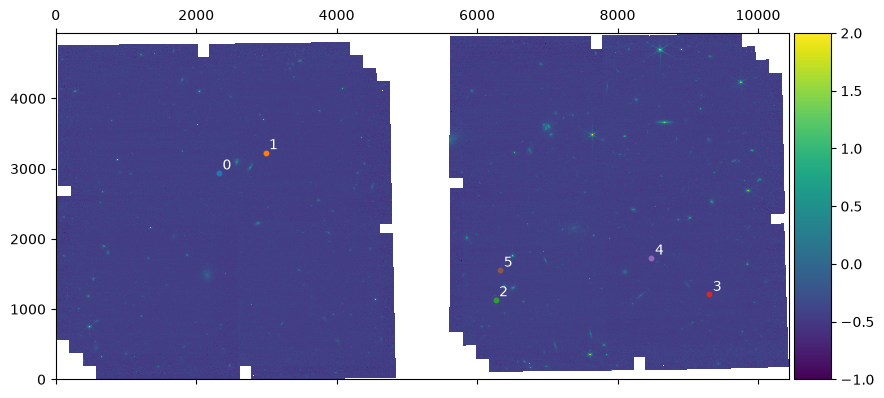

In [2]:
star_data_list, weight_data_list, noise_map_list = psf.get_psf_candidates(threshold_over_background=25000, 
                                                                          cutout_size=101,
                                                                          include_specific=[4, 9, 10, 18, 19, 20],
                                                                          save=False
                                                                        )

optax.adabelief: 100%|█████████████████████| 5000/5000 [01:38<00:00, 50.58it/s]


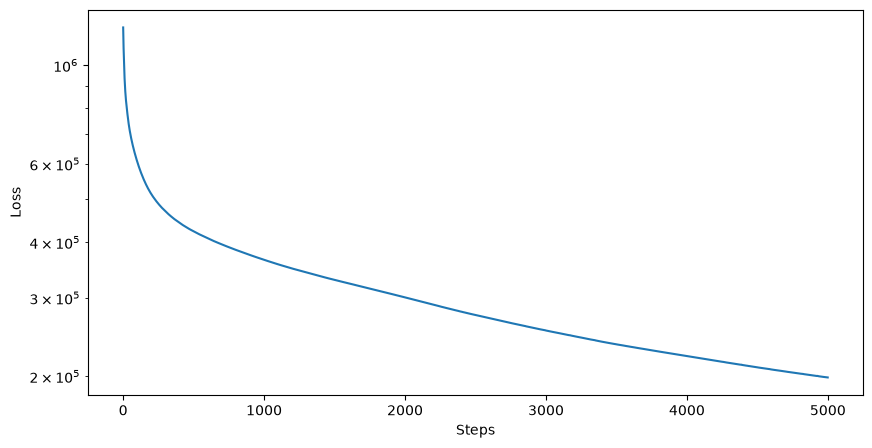

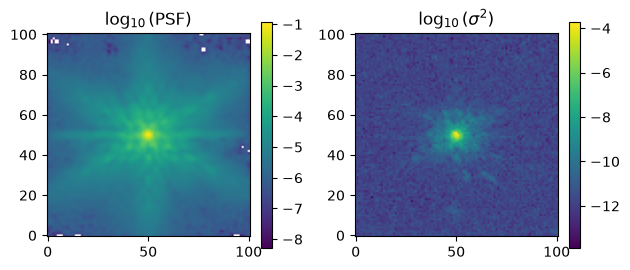

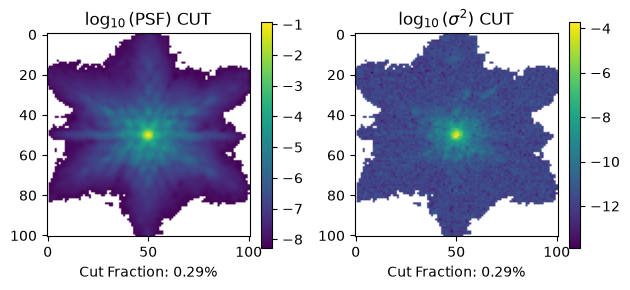

In [4]:
psf_starred, variance_map = psf.make_psf_starred(star_data_list=star_data_list,
                                               noise_map_list=noise_map_list,
                                               subsampling_factor=1,
                                               cut_threshold=1.7e-6,
                                               regularization_strength_scales=2.,
                                               regularization_strength_hf=2.,
                                               max_iterations=5000,
                                               save=True
                                            )

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:892: RuntimeWarning: invalid value encountered in log10
  im_psf = ax[0].imshow(np.log10(psf_guess), origin="lower", cmap="viridis")
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:896: RuntimeWarning: divide by zero encountered in log10
  im_variance = ax[1].imshow(np.log10(variance_map), origin="lower")


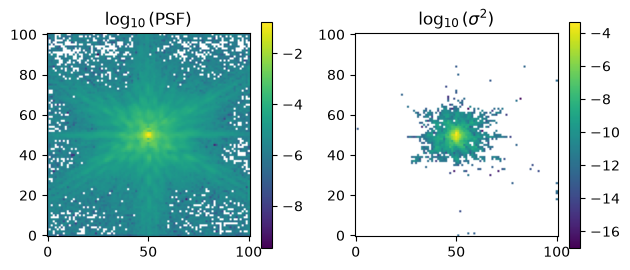

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:905: RuntimeWarning: divide by zero encountered in log10
  ax[0].imshow(np.log10(psf_cut))
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:909: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 4 Axes> than <Figure size 640x480 with 3 Axes> which fig.colorbar is called on.
  fig.colorbar(im_psf, ax=ax[0], fraction=0.05)
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:911: RuntimeWarning: divide by zero encountered in log10
  ax[1].imshow(np.log10(variance_map_cut))
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:914: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 4 Axes> than <Figure size 640x480 with 4 Axes> which fig.colorbar is called on.
  fig.colorbar(im_variance, ax=ax[1], fraction=0.05)


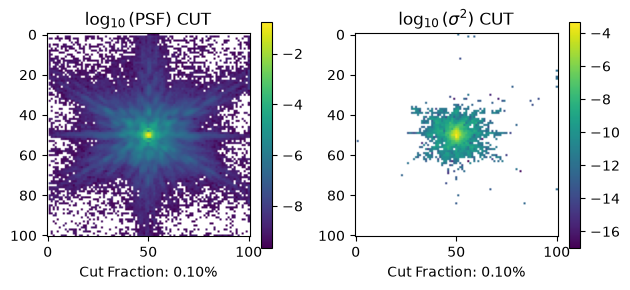

In [3]:
from dolphin.preprocessing.psf import PSF

io_directory="psfr_models/"
lens_name="WFI2033"
data_band="F115W"
full_image_file=f"full_data/full_image_{lens_name}_{data_band}.fits"

psf = PSF(io_directory=io_directory,
          lens_name=lens_name,
          data_band=data_band,
          instrument="JWST",
          full_image_file=full_image_file
         )

psf_psfr, variance_map_psfr = psf.make_psf_psfr(star_data_list=star_data_list,
                                                noise_map_list=noise_map_list,
                                                cut_threshold=1.7e-6,
                                                save=True
                                               )